<a href="https://colab.research.google.com/github/halilcankaroglu/yzm511-midterm-mlp/blob/main/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, sys, json
if "google.colab" in sys.modules:
    os.chdir("/content")
    if not os.path.exists("yzm511-midterm-mlp"):
        !git clone https://github.com/halilcankaroglu/yzm511-midterm-mlp.git
    %cd /content/yzm511-midterm-mlp
    try:
        from google.colab import userdata
        token = userdata.get("GH_TOKEN")
        !git remote set-url origin https://{token}@github.com/halilcankaroglu/yzm511-midterm-mlp.git
        !git config user.name "Halil Can Karoğlu"
        !git config user.email "GITHUB_EPOSTAN"
    except Exception:
        print("GH_TOKEN yok: yalnızca çalıştırma modu, push yapılmaz.")

SEEDS = json.load(open("configs/seeds.json")) if os.path.exists("configs/seeds.json") else None

/content/yzm511-midterm-mlp


In [ ]:
import pandas as pd

df = pd.read_csv("data/bank-additional.csv", sep=";")
print(df.shape)                  # beklenen: (4119, 21)
print(df.dtypes)
print(df["y"].value_counts())

df = df.drop(columns=["duration"])
print(df.duplicated().sum())

(4119, 21)
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object
y
no     3668
yes     451
Name: count, dtype: int64
19


In [ ]:
import os, json
import numpy as np

STUDENT_LAST5 = "29016"
BASE = int(STUDENT_LAST5 + "2026")   # 290162026

SEEDS = {
    "base": BASE,
    "split": BASE + 1,
    "outer_cv": BASE + 2,
    "inner_cv": BASE + 3,
    "early_stop": BASE + 4,
    "random_search": BASE + 5,
    "init": [BASE + 10, BASE + 11, BASE + 12],   # ilki ana model
}
os.makedirs("configs", exist_ok=True)
json.dump(SEEDS, open("configs/seeds.json", "w"), indent=2)
SEEDS

{'base': 290162026,
 'split': 290162027,
 'outer_cv': 290162028,
 'inner_cv': 290162029,
 'early_stop': 290162030,
 'random_search': 290162031,
 'init': [290162036, 290162037, 290162038]}

In [ ]:
from sklearn.model_selection import train_test_split

y = (df["y"] == "yes").astype(int)
idx = np.arange(len(df))
dev_idx, test_idx = train_test_split(
    idx, test_size=0.20, stratify=y, random_state=SEEDS["split"])

split = pd.DataFrame({"row_index": idx, "set": "dev", "y": y.values})
split.loc[test_idx, "set"] = "test"
os.makedirs("results", exist_ok=True)
split.to_csv("results/dataset_split.csv", index=False)

split.groupby("set")["y"].agg(["count", "sum", "mean"])

,count,sum,mean
set,,,
dev,3295,361,0.109560
test,824,90,0.109223


In [ ]:
X_cols = [c for c in df.columns if c != "y"]
dev_keys = set(map(tuple, df.iloc[dev_idx][X_cols].values))
n_twin = sum(tuple(r) in dev_keys for r in df.iloc[test_idx][X_cols].values)
print("Development'ta ikizi olan test satırı:", n_twin)

Development'ta ikizi olan test satırı: 7


EDA, bölüm 1 (yapı ve özel kodlar)

In [ ]:
dev = df.iloc[dev_idx].reset_index(drop=True)

num_cols = dev.select_dtypes("number").columns.tolist()
cat_cols = [c for c in dev.columns if c not in num_cols + ["y"]]

summary = pd.DataFrame({
    "tip": dev.dtypes.astype(str),
    "benzersiz": dev.nunique(),
    "unknown_sayisi": [(dev[c] == "unknown").sum() if c in cat_cols else 0 for c in dev.columns],
})
summary["unknown_%"] = (summary["unknown_sayisi"] / len(dev) * 100).round(2)
print(summary)
print("\nGerçek NaN:", dev.isna().sum().sum())
print("pdays = 999:", (dev["pdays"] == 999).sum(), f"(%{(dev['pdays'] == 999).mean()*100:.1f})")

                    tip  benzersiz  unknown_sayisi  unknown_%
age               int64         67               0       0.00
job              object         12              30       0.91
marital          object          4               7       0.21
education        object          7             137       4.16
default          object          3             627      19.03
housing          object          3              80       2.43
loan             object          3              80       2.43
contact          object          2               0       0.00
month            object         10               0       0.00
day_of_week      object          5               0       0.00
campaign          int64         24               0       0.00
pdays             int64         20               0       0.00
previous          int64          7               0       0.00
poutcome         object          3               0       0.00
emp.var.rate    float64         10               0       0.00
cons.pri

In [ ]:
u = dev[(dev["housing"] == "unknown") | (dev["loan"] == "unknown")]
print("housing veya loan unknown:", len(u),
      "| ikisi birden:", ((u["housing"] == "unknown") & (u["loan"] == "unknown")).sum())

print(pd.crosstab(dev["pdays"] == 999, dev["poutcome"]))
print(pd.crosstab(dev["pdays"] == 999, dev["previous"] > 0))

housing veya loan unknown: 80 | ikisi birden: 80
poutcome  failure  nonexistent  success
pdays                                  
False          14            0      111
True          349         2821        0
previous  False  True 
pdays                 
False         0    125
True       2821    349


EDA, bölüm 2: sınıf dağılımı ve sayısal istatistikler

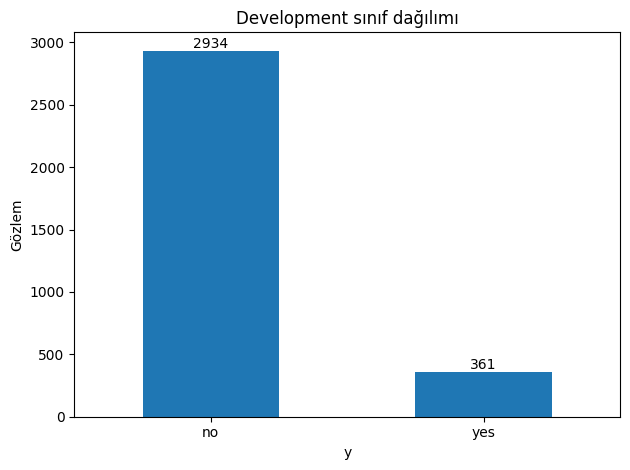

,ortalama,medyan,SD,IQR,min,maks
age,40.229,38.000,10.415,15.000,18.000,88.000
campaign,2.530,2.000,2.555,2.000,1.000,35.000
pdays,5.864,6.000,3.890,3.000,0.000,19.000
previous,0.190,0.000,0.547,0.000,0.000,6.000
emp.var.rate,0.084,1.100,1.565,3.200,-3.400,1.400
cons.price.idx,93.581,93.876,0.579,0.919,92.201,94.767
cons.conf.idx,-40.488,-41.800,4.596,6.300,-50.800,-26.900
euribor3m,3.623,4.857,1.733,3.627,0.635,5.045
nr.employed,5166.291,5191.000,73.782,129.000,4963.600,5228.100


In [ ]:
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)

# Sınıf dağılımı
ax = dev["y"].value_counts().plot.bar(rot=0)
ax.set_title("Development sınıf dağılımı"); ax.set_ylabel("Gözlem")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig("figures/eda_class_dist.png", dpi=150); plt.show()

# Sayısal özet (pdays 999 hariç tutularak ayrıca)
d = dev[num_cols].copy()
d["pdays"] = d["pdays"].where(d["pdays"] != 999)
stats = pd.DataFrame({
    "ortalama": d.mean(), "medyan": d.median(), "SD": d.std(),
    "IQR": d.quantile(.75) - d.quantile(.25), "min": d.min(), "maks": d.max(),
}).round(3)
stats.to_csv("results/eda_numeric_stats.csv")
stats

EDA, bölüm 3: histogram ve boxplot

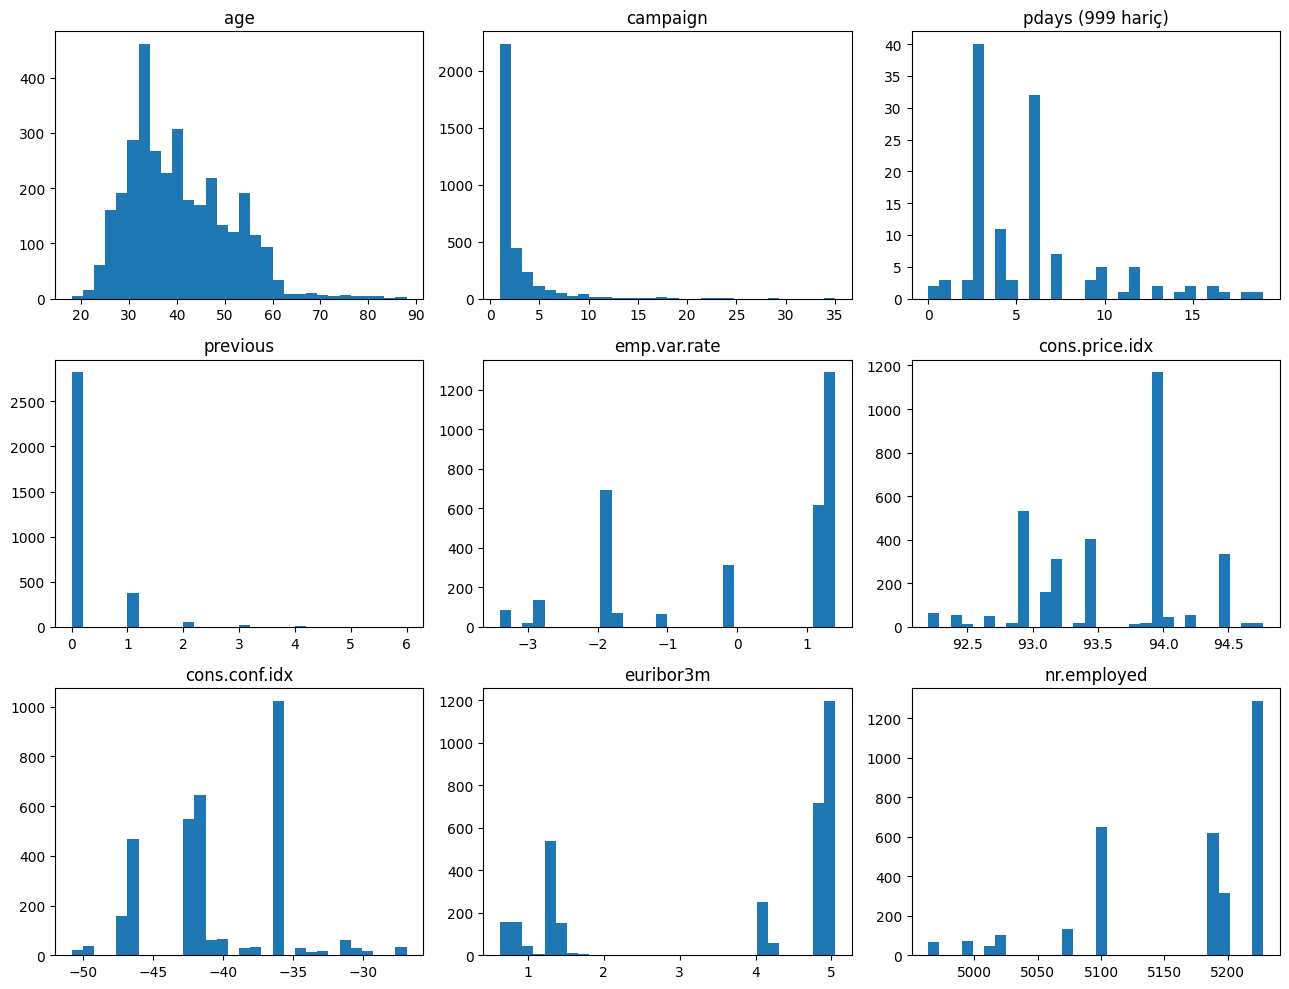

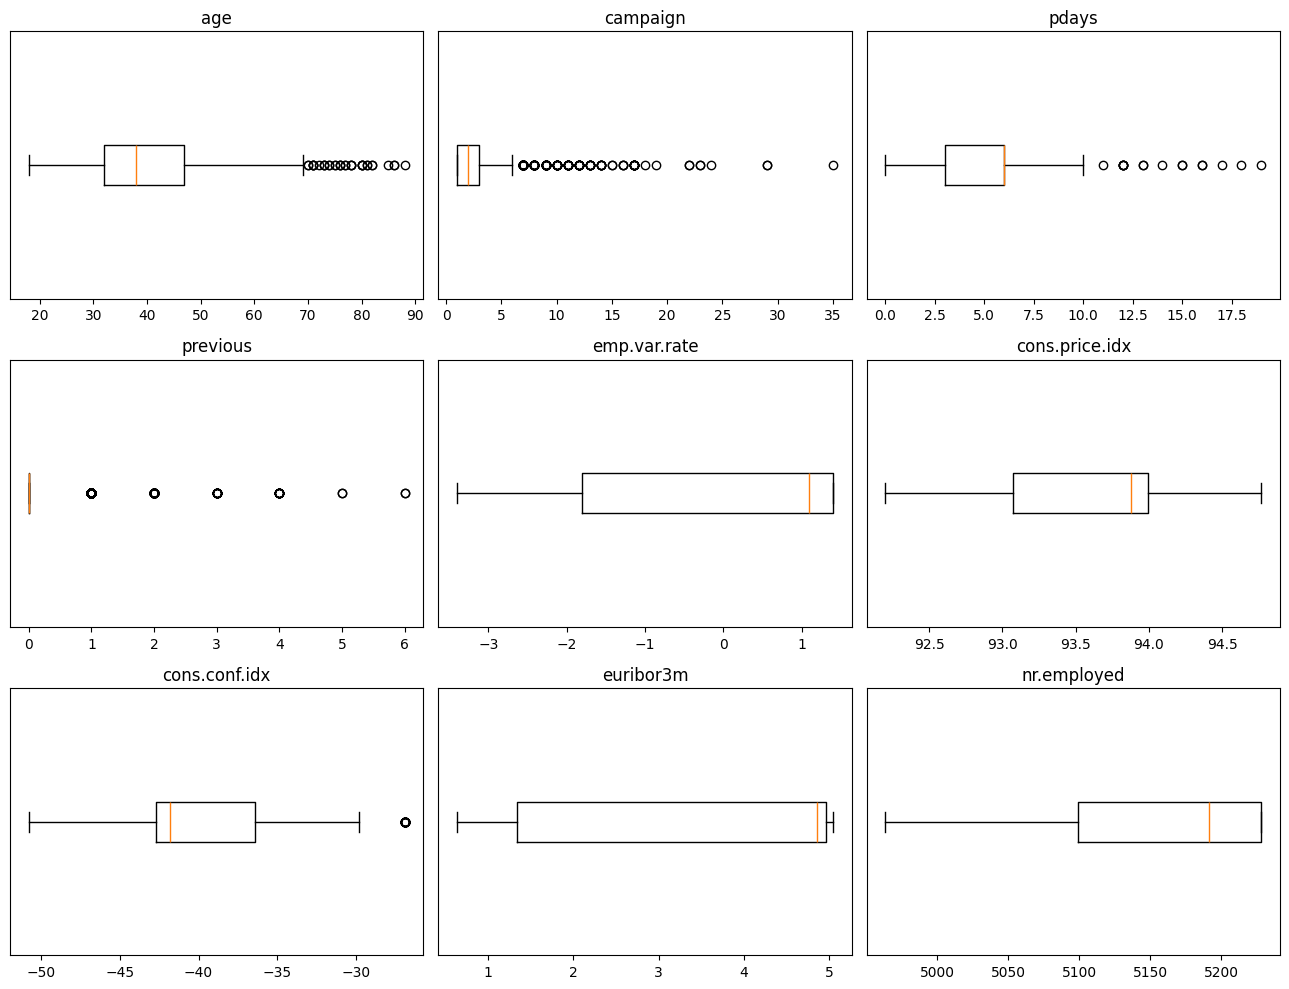

,aykiri_sayisi,aykiri_%
age,34,1.03
campaign,187,5.68
pdays,16,12.80
previous,474,14.39
emp.var.rate,0,0.00
cons.price.idx,0,0.00
cons.conf.idx,34,1.03
euribor3m,0,0.00
nr.employed,0,0.00


In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(d[c].dropna(), bins=30)
    ax.set_title(c + (" (999 hariç)" if c == "pdays" else ""))
plt.tight_layout(); plt.savefig("figures/eda_numeric_hist.png", dpi=150); plt.show()

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, c in zip(axes.ravel(), num_cols):
    ax.boxplot(d[c].dropna(), vert=False, whis=1.5)
    ax.set_title(c); ax.set_yticks([])
plt.tight_layout(); plt.savefig("figures/eda_numeric_box.png", dpi=150); plt.show()

# IQR kuralına göre aykırı sayısı (yalnızca işaretleme, silme yok)
q1, q3 = d.quantile(.25), d.quantile(.75)
iqr = q3 - q1
outliers = ((d < q1 - 1.5*iqr) | (d > q3 + 1.5*iqr)).sum()
pd.DataFrame({"aykiri_sayisi": outliers, "aykiri_%": (outliers / d.notna().sum() * 100).round(2)})

EDA, bölüm 4: kategorik özellikler

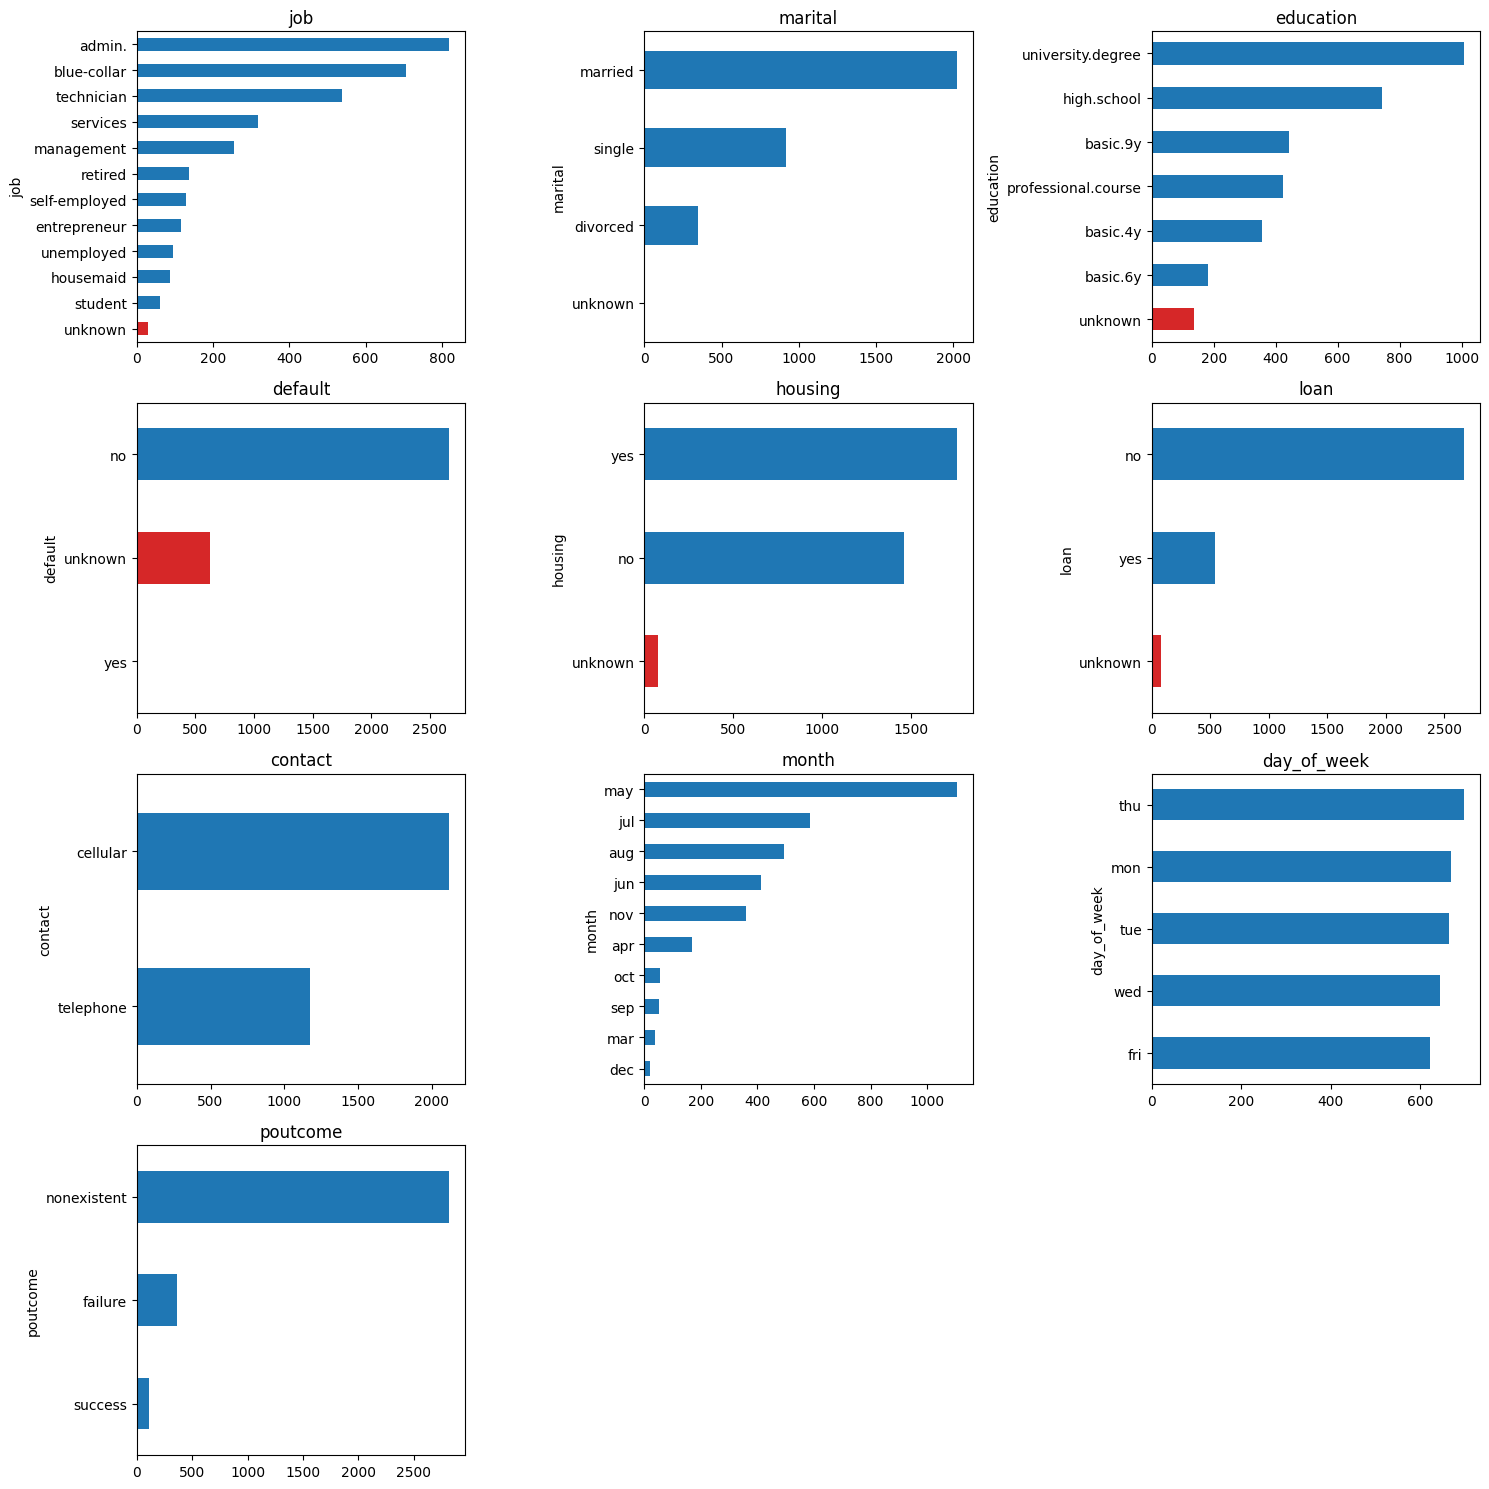

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(15, 15))
for ax, c in zip(axes.ravel(), cat_cols):
    vc = dev[c].value_counts()
    colors = ["tab:red" if k == "unknown" else "tab:blue" for k in vc.index]
    vc.plot.barh(ax=ax, color=colors)
    ax.set_title(c); ax.invert_yaxis()
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("figures/eda_categorical.png", dpi=150); plt.show()

freq = pd.concat({c: dev[c].value_counts() for c in cat_cols}, names=["ozellik", "kategori"]).rename("sayi").to_frame()
freq["%"] = (freq["sayi"] / len(dev) * 100).round(2)
freq.to_csv("results/eda_categorical_freq.csv")

EDA, bölüm 5: korelasyon ve hedefe göre betimsel karşılaştırma

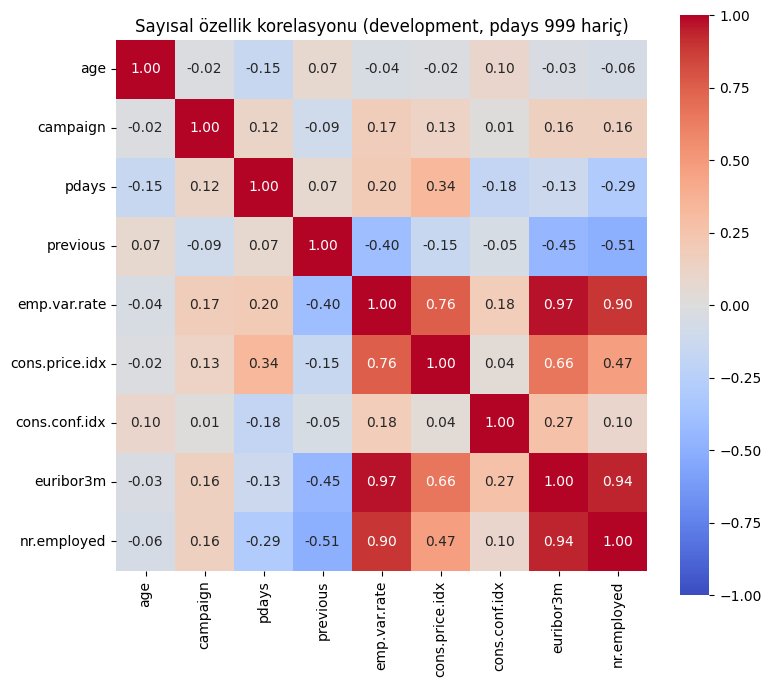

y,no,yes
age,38.000,39.000
campaign,2.000,2.000
previous,0.000,0.000
euribor3m,4.857,1.262
nr.employed,5195.800,5076.200


In [ ]:
import seaborn as sns

corr = d.corr()
plt.figure(figsize=(8, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Sayısal özellik korelasyonu (development, pdays 999 hariç)")
plt.tight_layout(); plt.savefig("figures/eda_corr.png", dpi=150); plt.show()

# Hedefe göre betimsel karşılaştırma (yalnızca betimleme, eleme yok)
by_y = d.assign(y=dev["y"]).groupby("y")[["age", "campaign", "previous", "euribor3m", "nr.employed"]].median().T
by_y

EDA, bölüm 6: hipotezler

## Deney hipotezleri (nested CV öncesinde yazıldı)

| # | Hipotez | EDA gerekçesi | Sınayan karşılaştırma |
|---|---|---|---|
| H1 | MinMaxScaler, StandardScaler'dan düşük iç CV AP verir. | `campaign` uzun kuyruklu; MinMax tek bir uç değere göre ölçekleyip diğer değerleri dar bir aralığa sıkıştırır. | M1 – M4 |
| H2 | Aynı LR (0,001) ile SGD+Momentum, Adam/AdamW'dan daha geç yakınsar ve daha düşük AP verir. | Girdi ölçekleri farklı; uyarlamalı optimizer'lar bundan daha az etkilenir. | M1, M2, M3 (AP ve best epoch) |
| H3 | Derin mimari (64,32), tek katmanlıdan (32,) anlamlı fark getirmez. | Sinyalin büyük kısmı yüksek korelasyonlu birkaç makro değişkende; eğitim kümesi küçük (~2.200 satır). | M1 – M5 |
| H4 | MLP, LogisticRegression'ı AP'de belirgin biçimde geçmez. | Baskın sinyal (faiz dönemi) neredeyse doğrusal ve tek boyutlu. | Outer CV: seçilen MLP – LogReg |

In [ ]:
!git pull --rebase
!git commit -m "Son kontrol commiti"
!git push

remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 5 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 305.87 KiB | 4.08 MiB/s, done.
From https://github.com/halilcankaroglu/yzm511-midterm-mlp
   943bd85..5fe51d6  main       -> origin/main
Updating 943bd85..5fe51d6
Fast-forward
 01_eda.ipynb      | 1440 +++++++++++++++++++++++++++++++++++++++++++++++++++++
 01_eda_ipyn.ipynb |  410 ---------------
 2 files changed, 1440 insertions(+), 410 deletions(-)
 create mode 100644 01_eda.ipynb
 delete mode 100644 01_eda_ipyn.ipynb
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date
